# 01 · Phase I error patterns (black box)
**AI & Vis UE · AI-aided pair: Dharmik & Sarang** · input: `results_validation.csv` from `00_baseline_finbert.ipynb`

Uses only FinBERT's inputs, outputs and softmax scores, plus the MiniLM/UMAP coordinates (a separate encoder).
Every pattern is tested on the full split (Fisher's exact test, 95% Wilson intervals), not on hand-picked tweets.

**Caveat:** the cue-word lists below are simple hand-made regexes, and the clusters come from k-means on 2D UMAP coordinates (k = 14 chosen by hand).
Both are tools for finding hypotheses, not ground truth.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)

BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b85", "#52514e"
CLS = {"Bearish": ORANGE, "Neutral": GRAY, "Bullish": BLUE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c8c7c0",
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110})

d = pd.read_csv("results_validation.csv")
d["err"] = ~d["correct"]; T = d.text.str.lower()
BASE = d.err.mean()
print(f"{len(d)} tweets · accuracy {1-BASE:.3f} · {d.err.sum()} errors")

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / den; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return c - h, c + h

2388 tweets · accuracy 0.725 · 656 errors


## F1 · Most errors are *Neutral* tweets that FinBERT gives a sentiment

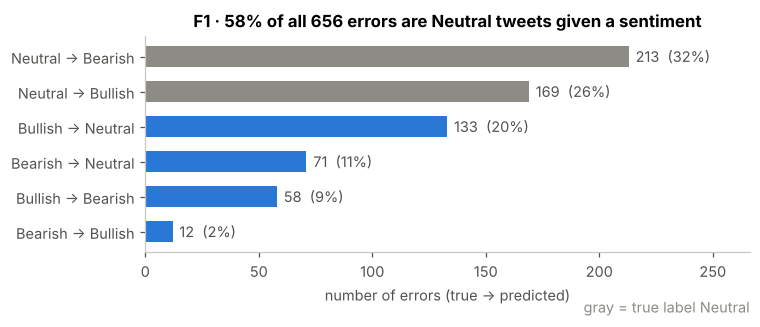

In [2]:
e = d[d.err]
et = e.groupby(["true", "pred"]).size().rename("n").reset_index().sort_values("n")
et["label"] = et.true + " → " + et.pred
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(et.label, et.n, color=[GRAY if t == "Neutral" else BLUE for t in et.true], height=.6)
for b, n in zip(bars, et.n):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height()/2, f"{n}  ({n/len(e):.0%})", va="center", color=INK)
ax.set_xlabel("number of errors (true → predicted)"); ax.set_xlim(0, et.n.max() * 1.25)
ax.set_title(f"F1 · {((e.true=='Neutral').mean()):.0%} of all {len(e)} errors are Neutral tweets given a sentiment")
ax.text(1, -0.28, "gray = true label Neutral", transform=ax.transAxes, ha="right", color=GRAY)
plt.tight_layout(); plt.savefig("F1_error_types.png", dpi=160); plt.show()

## F2 · FinBERT is overconfident

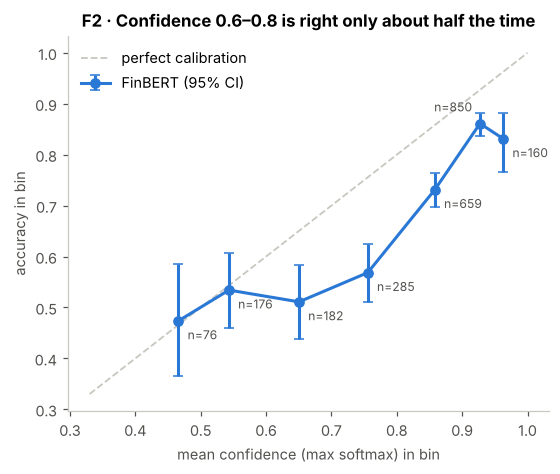

145 errors have confidence > 0.9


,cbin,n,acc,conf
0,"(0.33, 0.5]",76,0.473684,0.465925
1,"(0.5, 0.6]",176,0.534091,0.543197
2,"(0.6, 0.7]",182,0.510989,0.650370
3,"(0.7, 0.8]",285,0.568421,0.755621
4,"(0.8, 0.9]",659,0.731411,0.858245
5,"(0.9, 0.95]",850,0.861176,0.927276
6,"(0.95, 1.0]",160,0.831250,0.962887


In [3]:
bins = [.33, .5, .6, .7, .8, .9, .95, 1.0]
d["cbin"] = pd.cut(d.confidence, bins)
cal = d.groupby("cbin", observed=True).agg(n=("correct", "size"), acc=("correct", "mean"), conf=("confidence", "mean")).reset_index()
lo, hi = zip(*[wilson(a*n, n) for a, n in zip(cal.acc, cal.n)])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([.33, 1], [.33, 1], ls="--", c="#c8c7c0", lw=1.2, label="perfect calibration")
ax.errorbar(cal.conf, cal.acc, yerr=[cal.acc - np.array(lo), np.array(hi) - cal.acc], fmt="o-", c=BLUE, lw=2, ms=6, capsize=3, label="FinBERT (95% CI)")
for i, (x, y, n) in enumerate(zip(cal.conf, cal.acc, cal.n)):
    ax.annotate(f"n={n}", (x, y), xytext=(-30, 8) if i == len(cal) - 2 else (6, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("mean confidence (max softmax) in bin"); ax.set_ylabel("accuracy in bin")
ax.set_title("F2 · Confidence 0.6–0.8 is right only about half the time"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("F2_calibration.png", dpi=160); plt.show()
print(f"{(e.confidence > .9).sum()} errors have confidence > 0.9")
cal

## F3 · Hypotheses as slices: which tweet types are systematically harder?

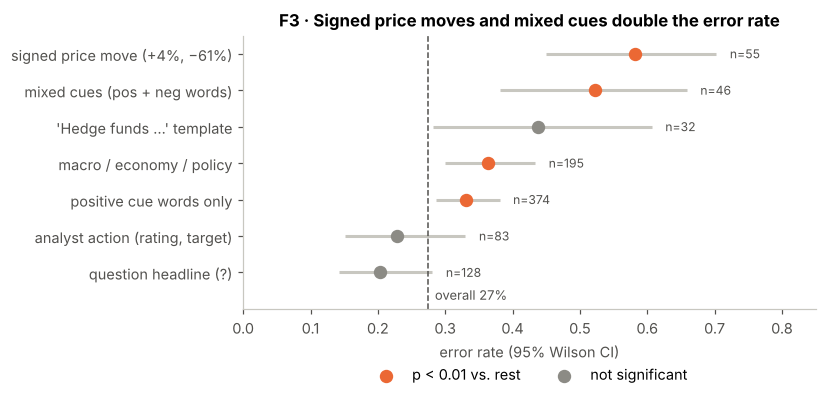

,slice,n,err,p,main_error
6,question headline (?),128,0.203,6.7e-02,Neutral → Bearish
5,"analyst action (rating, target)",83,0.229,3.8e-01,Bullish → Neutral
4,positive cue words only,374,0.332,8.1e-03,Neutral → Bullish
3,macro / economy / policy,195,0.364,4.4e-03,Neutral → Bearish
2,'Hedge funds …' template,32,0.438,4.6e-02,Bullish → Neutral
1,mixed cues (pos + neg words),46,0.522,3.5e-04,Neutral → Bearish
0,"signed price move (+4%, −61%)",55,0.582,1.7e-06,Bullish → Neutral


In [4]:
POS = r"\b(?:rise|rises|rose|surge|surges|soar|soars|jump|jumps|gain|gains|beat|beats|up|upgrade|upgraded|raises?|record|rally|rallies|strong|boost|higher|growth|profit|tops?)\b"
NEG = r"\b(?:fall|falls|fell|drop|drops|decline|declines|slide|slides|loss|losses|miss|misses|cut|cuts|downgrade|downgraded|lower|weak|plunge|sink|sinks|worst|risk|warns?|crisis|slump)\b"
hp, hn = T.str.contains(POS), T.str.contains(NEG)
d["cue"] = np.select([hp & hn, hp, hn], ["both", "pos only", "neg only"], "none")

SLICES = {
    "signed price move (+4%, −61%)": d.text.str.contains(r"[+-]\d+(?:\.\d+)?%"),
    "mixed cues (pos + neg words)": hp & hn,
    "'Hedge funds …' template": T.str.contains("hedge funds"),
    "macro / economy / policy": T.str.contains(r"\bfed\b|yield|treasury|gdp|inflation|unemployment|jobs|economy|recession|rate cut|central bank|deficit|oil price"),
    "positive cue words only": hp & ~hn,
    "analyst action (rating, target)": T.str.contains(r"upgrad|downgrad|price target|\btarget\b|cuts to|raises to|outperform|underperform|overweight|underweight|initiat"),
    "question headline (?)": d.text.str.contains(r"\?"),
}
rows = []
for name, m in SLICES.items():
    k, n = d.err[m].sum(), m.sum(); k2, n2 = d.err[~m].sum(), (~m).sum()
    p = fisher_exact([[k, n-k], [k2, n2-k2]])[1]; l, h = wilson(k, n)
    top = e[m[e.index]].groupby(["true", "pred"]).size()
    rows.append(dict(slice=name, n=n, err=k/n, lo=l, hi=h, p=p, main_error=" → ".join(top.idxmax()) if len(top) else ""))
S = pd.DataFrame(rows).sort_values("err")

fig, ax = plt.subplots(figsize=(7.6, 3.8))
sig = S.p < .01
ax.errorbar(S.err, S.slice, xerr=[S.err - S.lo, S.hi - S.err], fmt="none", ecolor="#c8c7c0", lw=2)
ax.scatter(S.err[sig], S.slice[sig], s=60, c=ORANGE, zorder=3, label="p < 0.01 vs. rest")
ax.scatter(S.err[~sig], S.slice[~sig], s=60, c=GRAY, zorder=3, label="not significant")
ax.axvline(BASE, ls="--", c=INK, lw=1); ax.text(BASE + .01, -0.75, f"overall {BASE:.0%}", color=INK, fontsize=8.5)
for _, r in S.iterrows(): ax.text(r.hi + .02, r.slice, f"n={r.n}", va="center", color=INK, fontsize=8)
ax.set_xlim(0, .85); ax.set_ylim(-1, len(S) - .5); ax.set_xlabel("error rate (95% Wilson CI)")
ax.set_title("F3 · Signed price moves and mixed cues double the error rate"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
plt.tight_layout(); plt.savefig("F3_slices.png", dpi=160); plt.show()
S.assign(err=S.err.round(3), p=S.p.map("{:.1e}".format)).drop(columns=["lo", "hi"])

In [5]:
# F3a · Signed price moves: FinBERT mostly ignores the sign and says Neutral
sign = d.text.str.extract(r"([+-])\d+(?:\.\d+)?%")[0]
s = d[sign.notna()].assign(sign=sign.dropna().map({"+": "+x%", "-": "−x%"}))
pd.crosstab([s.sign, s.true], s.pred, margins=True)

pred          Bearish  Bullish  Neutral  All
sign true                                   
+x%  Bullish        3       15       14   32
     Neutral        1        0        2    3
−x%  Bearish        5        2       10   17
     Bullish        1        0        1    2
     Neutral        0        0        1    1
All                10       17       28   55

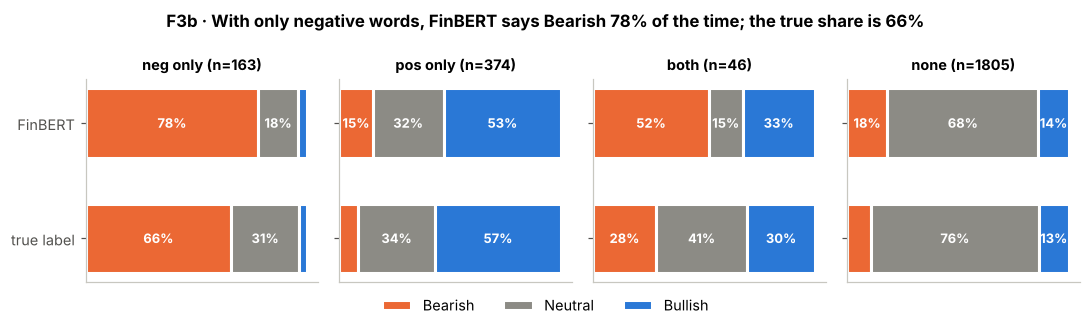

In [6]:
# F3b · Cue words: FinBERT follows sentiment words more strongly than the labels do
both = pd.concat({"true label": pd.crosstab(d.cue, d.true, normalize="index"),
                  "FinBERT":    pd.crosstab(d.cue, d.pred, normalize="index")}, axis=1).loc[["neg only", "pos only", "both", "none"]]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.9), sharey=True)
for ax, cue in zip(axes, both.index):
    for i, src in enumerate(["true label", "FinBERT"]):
        left = 0
        for c in ["Bearish", "Neutral", "Bullish"]:
            v = both.loc[cue, (src, c)]
            ax.barh(i, v, left=left, color=CLS[c], height=.6, edgecolor="white", linewidth=2, label=c if (cue == "neg only" and i == 0) else None)
            if v > .12: ax.text(left + v/2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8.5, weight="bold")
            left += v
    ax.set_title(f"{cue} (n={(d.cue == cue).sum()})", fontsize=9.5); ax.set_xticks([])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["true label", "FinBERT"])
fig.legend(loc="lower center", ncol=3, frameon=False)
fig.suptitle("F3b · With only negative words, FinBERT says Bearish 78% of the time; the true share is 66%", weight="bold", fontsize=11)
plt.tight_layout(rect=(0, .08, 1, 1)); plt.savefig("F3b_cue_words.png", dpi=160); plt.show()

## F4 · Error clusters on the 2D map: *what* the tweet is about matters
Clusters = k-means (k = 14) on the UMAP coordinates. Each one is described by its most over-represented terms (TF-IDF lift).

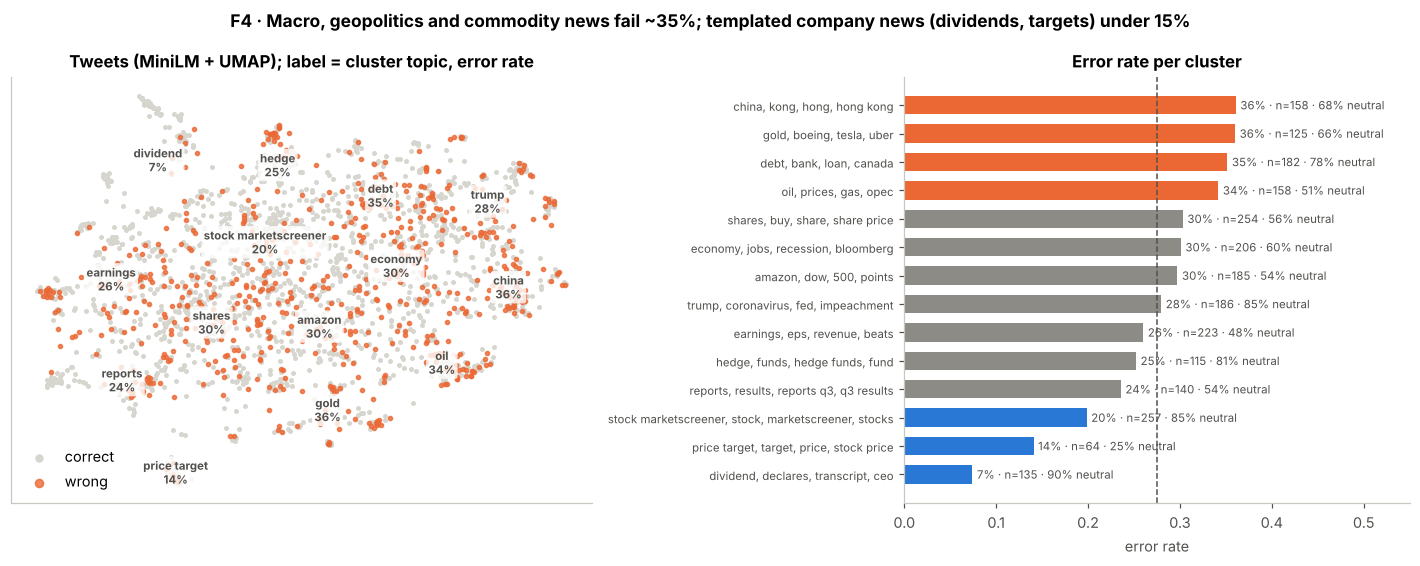

,cl,n,err,neutral,topic,main_error
2,2,158,0.36,0.68,"china, kong, hong, hong kong",Neutral → Bearish
0,0,125,0.36,0.66,"gold, boeing, tesla, uber",Neutral → Bullish
4,4,182,0.35,0.78,"debt, bank, loan, canada",Neutral → Bearish
6,6,158,0.34,0.51,"oil, prices, gas, opec",Neutral → Bearish
7,7,254,0.30,0.56,"shares, buy, share, share price",Neutral → Bullish
9,9,206,0.30,0.60,"economy, jobs, recession, bloomberg",Neutral → Bearish
13,13,185,0.30,0.54,"amazon, dow, 500, points",Bullish → Neutral
8,8,186,0.28,0.85,"trump, coronavirus, fed, impeachment",Neutral → Bearish
3,3,223,0.26,0.48,"earnings, eps, revenue, beats",Bullish → Neutral
1,1,115,0.25,0.81,"hedge, funds, hedge funds, fund",Neutral → Bullish


In [7]:
d["clean"] = d.text.str.replace(r"https?://\S+", "", regex=True).str.replace(r"\$[A-Za-z]+", "$TICK", regex=True)
d["cl"] = KMeans(n_clusters=14, n_init=10, random_state=0).fit_predict(d[["x", "y"]])
tf = TfidfVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2)); X = tf.fit_transform(d.clean)
voc = np.array(tf.get_feature_names_out()); g = X.mean(0).A1
prof = []
for c in range(14):
    m = (d.cl == c).values; s = d[m]
    terms = [t for t in voc[np.argsort(-(X[m].mean(0).A1 - g))] if t != "tick"][:4]
    mk = s[s.err].groupby(["true", "pred"]).size()
    prof.append(dict(cl=c, n=m.sum(), err=s.err.mean(), neutral=(s.true == "Neutral").mean(),
                     topic=", ".join(terms), main_error=" → ".join(mk.idxmax()) if len(mk) else "",
                     cx=s.x.median(), cy=s.y.median()))
P = pd.DataFrame(prof).sort_values("err", ascending=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
a1.scatter(d.x[~d.err], d.y[~d.err], s=5, c="#d6d5ce", label="correct")
a1.scatter(d.x[d.err], d.y[d.err], s=7, c=ORANGE, alpha=.8, label="wrong")
for _, r in P.iterrows():
    a1.text(r.cx, r.cy, f"{r.topic.split(',')[0]}\n{r.err:.0%}", ha="center", va="center", fontsize=7.5, weight="bold",
            color=INK, bbox=dict(boxstyle="round,pad=.2", fc="white", ec="none", alpha=.8))
a1.set_xticks([]); a1.set_yticks([]); a1.legend(frameon=False, loc="lower left", markerscale=2)
a1.set_title("Tweets (MiniLM + UMAP); label = cluster topic, error rate")
Q = P.sort_values("err")
a2.barh([f"{t}" for t in Q.topic], Q.err, color=[ORANGE if v > BASE + .05 else BLUE if v < BASE - .05 else GRAY for v in Q.err], height=.65)
a2.axvline(BASE, ls="--", c=INK, lw=1)
for i, (v, n, nu) in enumerate(zip(Q.err, Q.n, Q.neutral)): a2.text(v + .005, i, f"{v:.0%} · n={n} · {nu:.0%} neutral", va="center", fontsize=7.5, color=INK)
a2.set_xlim(0, .55); a2.set_xlabel("error rate"); a2.tick_params(axis="y", labelsize=7.5)
a2.set_title("Error rate per cluster")
fig.suptitle("F4 · Macro, geopolitics and commodity news fail ~35%; templated company news (dividends, targets) under 15%", weight="bold")
plt.tight_layout(); plt.savefig("F4_clusters.png", dpi=160); plt.show()
P.drop(columns=["cx", "cy"]).round(2)

In [8]:
# Read examples from the worst clusters: this is where the "why" comes from
for c in P.cl.head(3):
    print(f"\n=== cluster {c}: {P.set_index('cl').loc[c, 'topic']}")
    print(d[(d.cl == c) & d.err].sample(8, random_state=1)[["text", "true", "pred", "confidence"]].assign(text=lambda x: x.text.str[:95]).to_string(index=False))


=== cluster 2: china, kong, hong, hong kong
                                                                                           text    true    pred  confidence
                                 Hong Kong Stocks Nearly Recover Post-Holiday Losses With Rally Bullish Bearish    0.941421
China is planning a record sale of sovereign bonds in dollars, with a potential $6 billion offe Neutral Bullish    0.754562
                        Wuhan Doctor’s Death A Massive Headwind For China Coronavirus Sentiment Neutral Bearish    0.870683
                                    Futures climb on China plan to cut tariffs on U.S. products Bullish Bearish    0.752887
 China to raise penalties on IP theft in trade war compromise - SCMP\n\nhttps://t.co/hVY3zAtMg0 Neutral Bearish    0.585443
                         World's Top Steelmaker Sounds the Alarm as Virus Spreads Through China Neutral Bearish    0.825500
India is reviewing trade and goods agreements with its Southeast Asian neighbors after 

## Working interpretation (to discuss with the group)
- **Label meaning differs.** In this dataset *Neutral* seems to mean "no clear stance on a specific stock", so macro, political and commodity news is mostly Neutral even when its tone is clearly good or bad (F1, F4).
  FinBERT, trained on Financial PhraseBank, judges the *tone* of the sentence. So it gives a sentiment to these tweets.
- **Word cues beat composition.** FinBERT follows single sentiment words more strongly than the labels justify (F3b), and fails on mixed statements ("loss; revenue surges", "misses EPS, beats revenue") and reversals ("unemployment falls").
- **Numbers carry the sentiment, but FinBERT ignores them.** Tweets whose stance is a signed move ("−61% on FDA rejection", "+36% pre") are mostly predicted Neutral (F3a).
- **Overconfidence.** Wrong predictions still average 0.76 confidence, and 145 errors are above 0.9 (F2).

**Next checks:** rerun on the *train* split (~9.5k tweets, also unseen by FinBERT) to grow the small slices (signed %, n = 55; mixed cues, n = 46).
Build a small synthetic set (same sentence, sign or connector flipped) to test F3 causally. Then carry these groups into Phase II (attribution: which tokens drive the wrong predictions?).